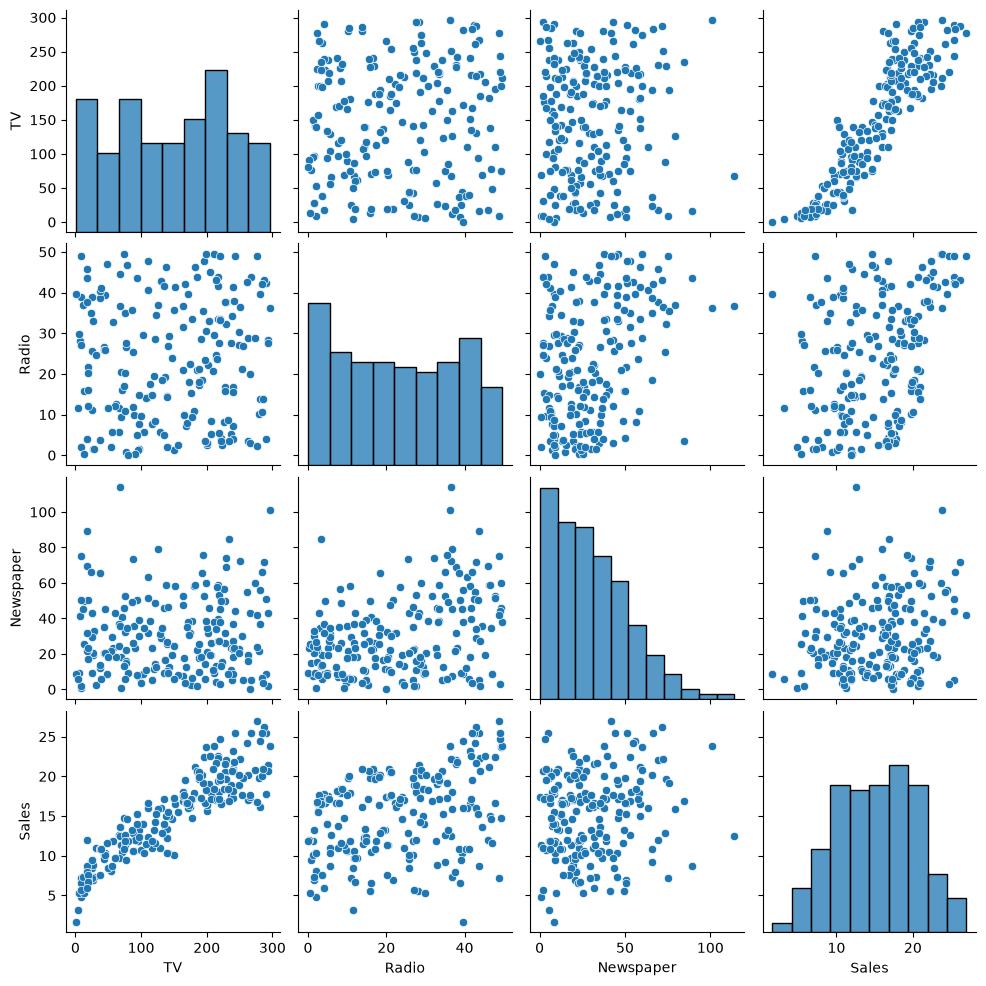

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import sklearn.model_selection as sk


df = pd.read_csv(filepath_or_buffer="./advertising.csv")
#df.info()
sns.pairplot(df)
plt.show()

In [20]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
X = df[['TV', 'Radio', 'Newspaper']]
y = df['Sales']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2137)
scaler = MinMaxScaler()

X_train_norm =scaler.fit_transform(X_train)
X_test_norm = scaler.transform(X_test)

X_model = LinearRegression().fit(X_train, y_train)
X_model_norm = LinearRegression().fit(X_train_norm, y_train)

mse_model = mean_squared_error(y_test, X_model.predict(X_test))
mse_model_norm = mean_squared_error(y_test, X_model_norm.predict(X_test_norm))

print(f'MSE model: {mse_model}')
print(f'MSE model with normalization: {mse_model_norm}')

print(f'Współczynniki surowe: {X_model.coef_}')
print(f'Współczynniki znormalizowane: {X_model_norm.coef_}')


MSE model: 3.121881760474992
MSE model with normalization: 3.1218817604749916
Współczynniki surowe: [0.05442617 0.11520582 0.00105471]
Współczynniki znormalizowane: [15.94142506  5.71420881  0.11992078]


W danych surowych wygląda na to, że radio jest 2x ważniejsze, ale jak okazuje się po znormalizowaniu, radio w rzeczywistości jest 3x mniej ważne od tv, które po prostu operowało na większej skali danych, stąd warto normalizować dane, bo wtedy realnie wyciągamy wnioski z danych, a nie tylko predykcję modelu, która przy regresji liniowej będzie taka sama